# Week 4
## Palmer Penguins Dataset

## 1. Dataset and justification

The **Palmer Penguins** dataset is useful for introductory data exploration because it is small, easy to understand, and contains both categorical and numerical variables as well as a small number of missing values.

For this practical, we use only five variables:

| Variable | Meaning | Conceptual type |
|---|---|---|
| `species` | Penguin species: Adelie, Chinstrap or Gentoo | Nominal categorical |
| `sex` | Penguin sex | Nominal categorical |
| `bill_length_mm` | Bill length in millimetres | Numerical continuous |
| `flipper_length_mm` | Flipper length in millimetres | Numerical continuous |
| `body_mass_g` | Body mass in grams | Numerical continuous |

Each row represents one penguin observation.

In [1]:
import warnings
warnings.filterwarnings('ignore')

## 2. Import the libraries

`pandas` is used for data manipulation, `matplotlib` for plotting, and `seaborn` for some statistical visualisations.

In [2]:
# pip install pandas matplotlib seaborn

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 3. Acquire the Penguins data

- The supplied `penguins.csv` file contains **344 penguin observations**.
- The original file has more columns, but this practical selects only five variables to keep the analysis simple.
- The Palmer Penguins data are publicly available and commonly used for teaching data science and statistics.

In [3]:
# Local CSV file used for this practical.
DATA_SOURCE = "penguins.csv"

# Read the CSV file.
penguins_df = pd.read_csv(DATA_SOURCE)

# Display the first five rows of the original dataset.
penguins_df.head()

,Unnamed: 0,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [4]:
# Select only five variables for this practical.
df_chosen = penguins_df[[
    "species",
    "sex",
    "bill_length_mm",
    "flipper_length_mm",
    "body_mass_g"
]].copy()

df_chosen.head()

,species,sex,bill_length_mm,flipper_length_mm,body_mass_g
0,Adelie,male,39.1,181.0,3750.0
1,Adelie,female,39.5,186.0,3800.0
2,Adelie,female,40.3,195.0,3250.0
3,Adelie,NaN,NaN,NaN,NaN
4,Adelie,female,36.7,193.0,3450.0


In [5]:
df_chosen.isnull().sum()

species               0
sex                  11
bill_length_mm        2
flipper_length_mm     2
body_mass_g           2
dtype: int64

# Understanding Skewness and p-Values

## 1. What is Skewness?

**Skewness measures how symmetrical or asymmetrical a data distribution is.**

A perfectly symmetrical distribution has a skewness of zero.

### Formula for Skewness

One commonly used formula is:

$$
\text{Skewness} = \frac{1}{n}\sum_{i=1}^{n}\left(\frac{x_i-\bar{x}}{\sigma}\right)^3
$$

Where:

- $n$ = Number of observations
- $x_i$ = Individual observation
- $\bar{x}$ = Mean of observations
- $\sigma$ = Population standard deviation

**Note:** The `skew()` function in pandas calculates a bias-adjusted sample skewness, so its result may differ slightly.

### Types of Skewness

| Skewness | Interpretation | Distribution Shape |
|----------|----------------|-------------------|
| Skewness ≈ 0 | Approximately symmetrical | Similar left and right tails |
| Skewness > 0 | Positively skewed | Longer right tail |
| Skewness < 0 | Negatively skewed | Longer left tail |

## 2. What is a p-Value?

A **p-value measures how unusual the observed test result would be if the null hypothesis were true.**

In this tutorial, we use the **Shapiro-Wilk Normality Test** to determine whether numerical variables follow a normal distribution.

### Hypotheses

**Null Hypothesis (H₀):**

The population data follow a normal distribution.

**Alternative Hypothesis (H₁):**

The population data do not follow a normal distribution.

### Interpreting the p-Value

We use a significance level of 0.05 (5%).

| p-Value | Statistical Decision | Interpretation |
|---------|----------------------|----------------|
| p > 0.05 | Fail to reject H₀ | Insufficient evidence against normality |
| p ≤ 0.05 | Reject H₀ | Evidence that the distribution is not normal |

### Example 1: p-value = 0.003

Since:

$$
0.003 < 0.05
$$

We reject the null hypothesis.

**Conclusion:** There is statistical evidence that the distribution is not normal.

### Example 2: p-value = 0.25

Since:

$$
0.25 > 0.05
$$

We fail to reject the null hypothesis.

**Conclusion:** There is insufficient statistical evidence to conclude that the distribution is not normal.

## 3. Which Imputation Method is Better?

The distribution of numerical variables can help us decide which imputation technique to use.

| Data Distribution | Recommended Imputation |
|-------------------|------------------------|
| Approximately symmetrical, without significant outliers | Mean Imputation |
| Skewed distribution | Median Imputation |
| Distribution containing strong outliers | Median Imputation |
| Categorical variables | Mode Imputation |

### Mean Imputation

Mean imputation replaces missing values with the average of the observed values.

$$
\bar{x} = \frac{\sum_{i=1}^{n}x_i}{n}
$$

**Suitable for:** Approximately symmetrical distributions without strong outliers.

### Median Imputation

Median imputation replaces missing values with the middle value of the sorted observations.

**Suitable for:** Skewed distributions or variables containing outliers.

### Mode Imputation

Mode imputation replaces missing values with the most frequently occurring value.

**Suitable for:** Categorical variables such as species, gender, or island.

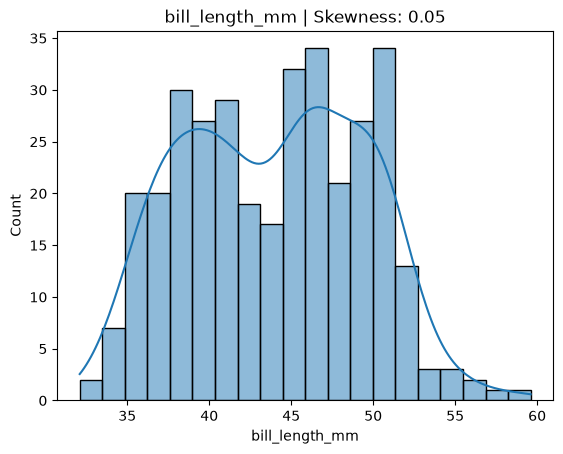

bill_length_mm: Not Normal
Skewness: 0.05 | p-value: 0.0000
Suggested imputation: Median


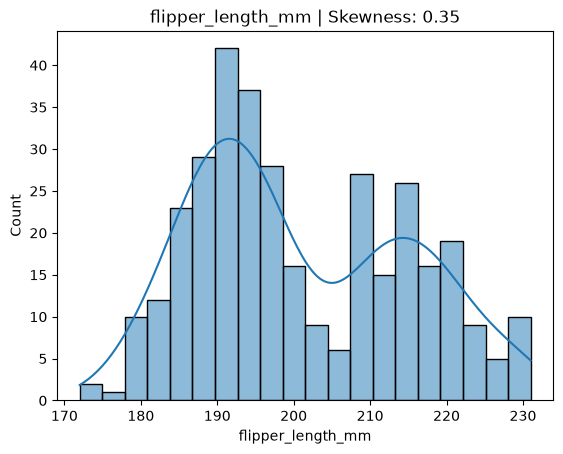

flipper_length_mm: Not Normal
Skewness: 0.35 | p-value: 0.0000
Suggested imputation: Median


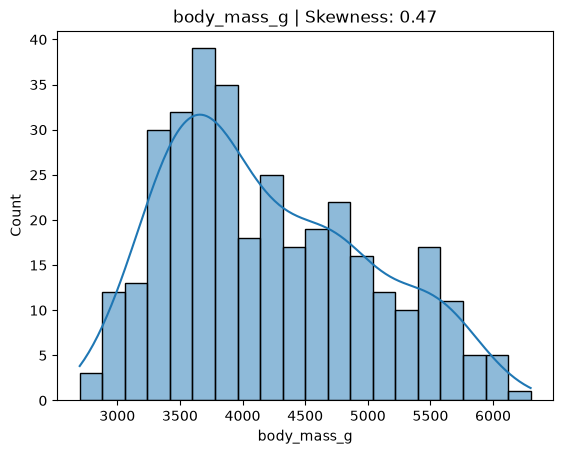

body_mass_g: Not Normal
Skewness: 0.47 | p-value: 0.0000
Suggested imputation: Median


In [6]:
from scipy.stats import shapiro                               # Import Shapiro-Wilk normality test

numeric_cols = df_chosen.select_dtypes(include = "number")    # Select numerical columns only

for col in numeric_cols:                                      # Check each numerical variable
    data = df_chosen[col].dropna()                            # Remove missing values temporarily

    skew = data.skew()                                                                      # Calculate skewness
    p = shapiro(data).pvalue                                                                # Calculate normality test p-value

    sns.histplot(data, kde = True, bins = 20)                                               # Plot histogram with density curve
    plt.title(f"{col} | Skewness: {skew:.2f}")                                              # Display variable name and skewness
    plt.show()                                                                              # Display graph

    print(f"{col}: Normal" if p > 0.05 else f"{col}: Not Normal")                           # Interpret normality test
    print(f"Skewness: {skew:.2f} | p-value: {p:.4f}")                                       # Display statistical results
    print("Suggested imputation:", "Mean" if p > 0.05 and abs(skew) < 0.5 else "Median")    # Suggest method

### Interpretation of the Results

| Measurement | Interpretation |
|-------------|----------------|
| p-value > 0.05 | Normality is not rejected |
| p-value ≤ 0.05 | Evidence against normality |
| Skewness close to 0 | Approximately symmetrical distribution |
| Skewness > 0 | Positively skewed (right-skewed) |
| Skewness < 0 | Negatively skewed (left-skewed) |

### Which Imputation Method is Better?

- **Mean Imputation:** Suitable for approximately normal, symmetrical distributions without significant outliers.
- **Median Imputation:** Generally preferable for skewed distributions or variables containing outliers.

### Important Note for the Penguins Dataset

Measurements vary significantly between penguin species. Even when the overall distribution is not normal, imputing missing values using the **median within each species** can be more appropriate than using one median for all penguins.

## 4. Understand the dataset: observations and variables

An **observation** is one entity being studied. Here, one row represents one penguin.

A **variable** is a characteristic that can take different values. Here, columns such as `species`, `sex`, and `body_mass_g` are variables/attributes.

In [7]:
# Shape returns: (number of rows, number of columns).
print("Dataset shape:", df_chosen.shape)
print("Number of observations:", df_chosen.shape[0])
print("Number of variables:", df_chosen.shape[1])

Dataset shape: (344, 5)
Number of observations: 344
Number of variables: 5


## 5. Examine column names, storage types and conceptual data types

`species` and `sex` are stored as text/object values and are conceptually categorical variables. The three measurement variables are stored numerically.

In [8]:
# Display a fuller summary, including non-null counts.
df_chosen.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   sex                333 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   flipper_length_mm  342 non-null    float64
 4   body_mass_g        342 non-null    float64
dtypes: float64(3), str(2)
memory usage: 17.4 KB


In [9]:
# Identify columns that pandas stores as numerical or categorical/text.
numerical_columns = df_chosen.select_dtypes(include="number").columns.tolist()
categorical_columns = df_chosen.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numerical storage columns:", numerical_columns)
print("Categorical/text storage columns:", categorical_columns)

Numerical storage columns: ['bill_length_mm', 'flipper_length_mm', 'body_mass_g']
Categorical/text storage columns: ['species', 'sex']


### Conceptual classification

- `species` -> nominal categorical
- `sex` -> nominal categorical
- `bill_length_mm` -> numerical continuous
- `flipper_length_mm` -> numerical continuous
- `body_mass_g` -> numerical continuous

## 6. Explore unique values

In [10]:
# Count the number of distinct non-missing values in each variable.
print("Number of unique values per variable:")
print(df_chosen.nunique(dropna=True))

print("\nSpecies categories:")
print(df_chosen["species"].unique())

print("\nSex categories, including missing values:")
print(df_chosen["sex"].unique())

Number of unique values per variable:
species                3
sex                    2
bill_length_mm       164
flipper_length_mm     55
body_mass_g           94
dtype: int64

Species categories:
<ArrowStringArray>
['Adelie', 'Gentoo', 'Chinstrap']
Length: 3, dtype: str

Sex categories, including missing values:
<ArrowStringArray>
['male', 'female', nan]
Length: 3, dtype: str


## 7. Data-quality check: missing values

We count missing values and then calculate the percentage missing in each variable.

In [11]:
# Count missing/null values in each column.
missing_count = df_chosen.isnull().sum()

# Calculate the percentage missing in each column.
missing_percentage = df_chosen.isnull().mean() * 100

missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percentage.round(2)
})

print(missing_summary)

                   Missing Count  Missing Percentage
species                        0                0.00
sex                           11                3.20
bill_length_mm                 2                0.58
flipper_length_mm              2                0.58
body_mass_g                    2                0.58


### Interpretation of missing values

Before any cleaning:

- `sex` has **11 missing values**, about **3.20%** of the 344 observations.
- `bill_length_mm` has **2 missing values**, about **0.58%**.
- `flipper_length_mm` has **2 missing values**, about **0.58%**.
- `body_mass_g` has **2 missing values**, about **0.58%**.
- `species` has no missing values.

The amount of missing data is small, so all five selected variables can be retained for this introductory practical.

## 8. Missing-value decision criteria

There is **no universal percentage rule** at which a column must be deleted. The decision should consider:

- the proportion of missing values;
- why values are missing;
- whether the variable is important to the analysis;
- whether meaningful information can still be extracted; and
- whether an imputation method can be defended.

A simple classroom guideline is shown below. It should be treated as a guide rather than a fixed rule.

| Missingness | Possible classroom decision |
|---:|---|
| < 5% | Usually retain; investigate and possibly impute |
| 5%–20% | Retain with caution; justify any imputation |
| 20%–50% | Investigate carefully; missingness is substantial |
| > 50% | Consider removal or transformation |
| > 70% | Strong candidate for removal unless especially valuable |

## 9. Decide whether any selected column should be removed

All five selected variables have low missingness. Therefore, **no selected variable is removed** at this stage.

In [12]:
# Keep all five selected variables because their missingness is low.
print("Columns retained for analysis:")
print(df_chosen.columns.tolist())

Columns retained for analysis:
['species', 'sex', 'bill_length_mm', 'flipper_length_mm', 'body_mass_g']


## 10. Check duplicate observations

Duplicate checking must be interpreted carefully. Because the selected subset does not contain a unique penguin identifier, two different penguins could theoretically have exactly the same values across these five variables.

Therefore, duplicate rows should be investigated before deletion.

In [13]:
# Count rows that are identical across the current set of columns.
duplicate_count = df_chosen.duplicated().sum()
print("Duplicate rows across the current variables:", duplicate_count)

# Display duplicated rows for inspection.
display(df_chosen[df_chosen.duplicated(keep=False)])

Duplicate rows across the current variables: 1


,species,sex,bill_length_mm,flipper_length_mm,body_mass_g
308,Chinstrap,female,42.5,187.0,3350.0
330,Chinstrap,female,42.5,187.0,3350.0


In [14]:
# For this classroom practical, remove exact duplicates across the selected variables.
df_chosen = df_chosen.drop_duplicates()

print("Dataset shape after removing exact duplicates:", df_chosen.shape)

Dataset shape after removing exact duplicates: (343, 5)


## 11. Descriptive statistics before imputation

`describe()` summarises numerical variables using count, mean, standard deviation, minimum, quartiles and maximum.

Notice that the counts for the measurement variables are slightly lower than the total number of rows because some values are missing at this stage.

In [15]:
# Summary statistics for numerical variables.
df_chosen.describe()

,bill_length_mm,flipper_length_mm,body_mass_g
count,341.000000,341.000000,341.000000
mean,43.926100,200.956012,4204.252199
std,5.467061,14.062083,801.799601
min,32.100000,172.000000,2700.000000
25%,39.200000,190.000000,3550.000000
50%,44.500000,197.000000,4050.000000
75%,48.500000,213.000000,4750.000000
max,59.600000,231.000000,6300.000000


## 12. Handle missing numerical values

The three measurement variables contain only a small number of missing values. For this practical, we use the **median** for each numerical variable because it is simple to explain and is less influenced by extreme values than the mean.

In [16]:
# List the numerical variables that contain missing values.
numerical_to_impute = [
    "bill_length_mm",
    "flipper_length_mm",
    "body_mass_g"
]

# Replace missing values in each numerical column with its median.
for column in numerical_to_impute:
    median_value = df_chosen[column].median()
    print(f"Median {column}: {median_value}")
    df_chosen[column] = df_chosen[column].fillna(median_value)

Median bill_length_mm: 44.5
Median flipper_length_mm: 197.0
Median body_mass_g: 4050.0


## 13. Handle missing `sex`

`sex` is categorical and has a small number of missing values. A simple introductory strategy is to replace missing values with the **mode** (the most common category).

For a real research analysis, the reason for the missing values should be investigated before choosing an imputation method.

In [17]:
# Find the most common sex category.
mode_sex = df_chosen["sex"].mode()[0]
print("Most common sex category:", mode_sex)

# Fill missing sex values with the mode.
df_chosen["sex"] = df_chosen["sex"].fillna(mode_sex)

Most common sex category: male


## 14. Verify the cleaning

A good data-cleaning process should follow:

**Detect -> Understand -> Treat -> Verify**

We now check that the intended missing values have been handled.

In [18]:
# Verify missing values after our treatments.
print("Missing values after cleaning:")
print(df_chosen.isnull().sum())

Missing values after cleaning:
species              0
sex                  0
bill_length_mm       0
flipper_length_mm    0
body_mass_g          0
dtype: int64


## 15. Turn raw data into information

Raw values become more useful when they are summarised or interpreted. For example, individual body-mass measurements can be summarised as an overall average or compared across species.

In [19]:
# Example 1: average body mass.
average_mass = df_chosen["body_mass_g"].mean()
print("Average penguin body mass:", round(average_mass, 2), "g")

# Example 2: average bill length.
average_bill = df_chosen["bill_length_mm"].mean()
print("Average bill length:", round(average_bill, 2), "mm")

# Example 3: number of penguins in each species.
print("\nNumber of penguins by species:")
print(df_chosen["species"].value_counts())

# Example 4: average body mass by species.
print("\nAverage body mass by species:")
print(df_chosen.groupby("species")["body_mass_g"].mean().round(2))

Average penguin body mass: 4203.35 g
Average bill length: 43.93 mm

Number of penguins by species:
species
Adelie       152
Gentoo       124
Chinstrap     67
Name: count, dtype: int64

Average body mass by species:
species
Adelie       3702.96
Chinstrap    3738.81
Gentoo       5067.74
Name: body_mass_g, dtype: float64


## 16. Filtering observations

Filtering selects rows that meet a condition. This is useful for answering questions about subgroups.

In [20]:
# Adelie penguins.
adelie_penguins = df_chosen[df_chosen["species"] == "Adelie"]
print("Number of Adelie penguins:", len(adelie_penguins))

display(adelie_penguins.head())

Number of Adelie penguins: 152


,species,sex,bill_length_mm,flipper_length_mm,body_mass_g
0,Adelie,male,39.1,181.0,3750.0
1,Adelie,female,39.5,186.0,3800.0
2,Adelie,female,40.3,195.0,3250.0
3,Adelie,male,44.5,197.0,4050.0
4,Adelie,female,36.7,193.0,3450.0


In [21]:
# Female penguins.
female_penguins = df_chosen[df_chosen["sex"] == "female"]
print("Female penguins:", len(female_penguins))

# Female Gentoo penguins: two conditions combined with &.
female_gentoo = df_chosen[
    (df_chosen["sex"] == "female") &
    (df_chosen["species"] == "Gentoo")
]
print("Female Gentoo penguins:", len(female_gentoo))

Female penguins: 164
Female Gentoo penguins: 58


# 17. Data visualisation

### Species distribution

A bar chart is suitable for showing the frequency of categories.

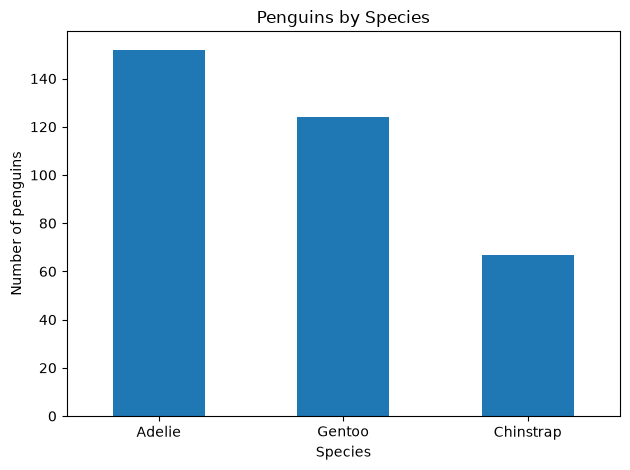

In [22]:
# Bar chart of penguin counts by species.
df_chosen["species"].value_counts().plot(kind = "bar")
plt.title("Penguins by Species")
plt.xlabel("Species")
plt.ylabel("Number of penguins")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Bill-length distribution

A histogram is appropriate for examining the distribution of a continuous numerical variable.

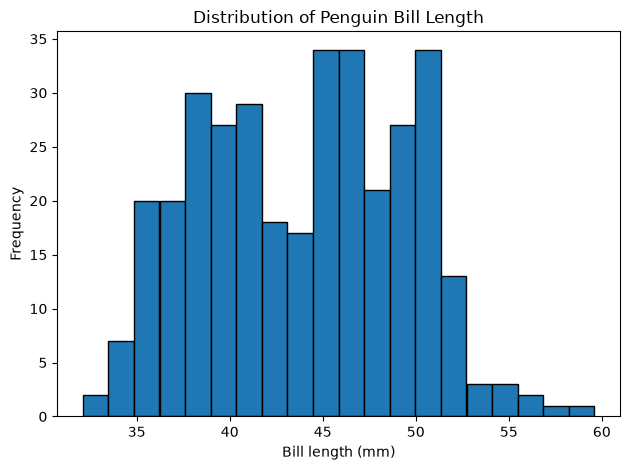

In [23]:
# Histogram of bill length after median imputation.
plt.hist(df_chosen["bill_length_mm"], bins = 20, edgecolor = "black")
plt.title("Distribution of Penguin Bill Length")
plt.xlabel("Bill length (mm)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

### Body-mass distribution

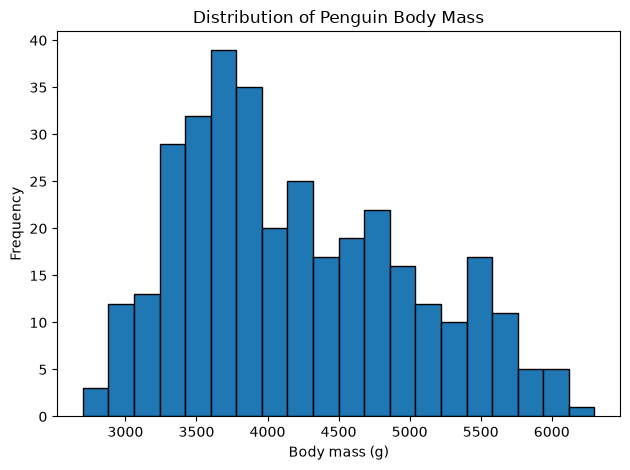

In [24]:
# Histogram of body mass.
plt.hist(df_chosen["body_mass_g"], bins = 20, edgecolor = "black")
plt.title("Distribution of Penguin Body Mass")
plt.xlabel("Body mass (g)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

## 18. Compare a numerical variable across categories

A boxplot can be used to compare the distribution of a numerical variable across categories.

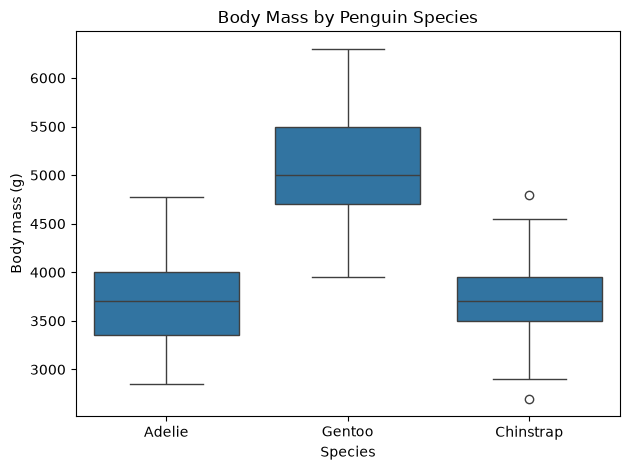

In [25]:
# Compare body mass across penguin species.
sns.boxplot(data = df_chosen, x = "species", y = "body_mass_g")
plt.title("Body Mass by Penguin Species")
plt.xlabel("Species")
plt.ylabel("Body mass (g)")
plt.tight_layout()
plt.show()

## 19. Correlation among numerical variables

Correlation summarises the strength and direction of a linear relationship between numerical variables. It does **not** establish causation.

Here we calculate correlations only among the three continuous measurement variables.

In [26]:
# Select numerical measurement variables for a simple correlation demonstration.
numeric_df = df_chosen[[
    "bill_length_mm",
    "flipper_length_mm",
    "body_mass_g"
]]

correlation_matrix = numeric_df.corr()
correlation_matrix.round(2)

,bill_length_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.00,0.66,0.60
flipper_length_mm,0.66,1.00,0.87
body_mass_g,0.60,0.87,1.00


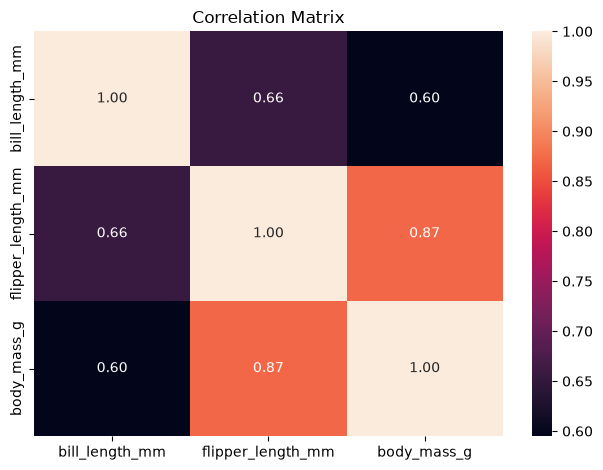

In [27]:
# Visualise the correlation matrix.
sns.heatmap(correlation_matrix, annot=True, fmt=".2f")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

## 20. Using `groupby()` to extract useful information

`groupby()` brings rows with the same category together. We can then calculate useful summaries, such as the **average body mass for each species**. The table answers a question, rather than showing every individual penguin.

* Which species has the highest average body mass?

In [28]:
# Average body mass for each species (in grams).
df_chosen.groupby("species")["body_mass_g"].mean()

species
Adelie       3702.960526
Chinstrap    3738.805970
Gentoo       5067.741935
Name: body_mass_g, dtype: float64

We can also group by **two categories**. For example, the table below gives the number of records in each combination of species and sex. Note that the `sex` values were filled earlier in this notebook, so these counts include imputed values.

In [29]:
# Number of penguins in each species/sex group.
df_chosen.groupby(["species", "sex"]).size()

species    sex   
Adelie     female    73
           male      79
Chinstrap  female    33
           male      34
Gentoo     female    58
           male      66
dtype: int64

## 21. Feature selection using the F-score (`SelectKBest`)

**Feature selection** means finding the input columns most strongly associated with a chosen outcome. Here, we use the species as the outcome and the three numerical measurements as possible predictors.

`SelectKBest` with `f_classif` calculates an **ANOVA F-score** for each measurement. A larger F-score suggests the average value differs more clearly among species. This is a quick *ranking* exercise, not proof that a feature causes species differences or that a predictive model will work well.

We exclude `species` from the input features because it is the answer we are trying to predict. We also leave out `sex` so the first example needs no categorical encoding. The measurements have already had their missing values filled earlier.

In [30]:
from sklearn.feature_selection import SelectKBest, f_classif

# Input measurements and the category we want to distinguish.
X = df_chosen[["bill_length_mm", "flipper_length_mm", "body_mass_g"]]
y = df_chosen["species"]

# Choose the two highest-ranked features by ANOVA F-score.
selector = SelectKBest(score_func = f_classif, k = 2)
selector.fit(X, y)

# Show each feature's score, highest first.
scores = pd.Series(selector.scores_, index = X.columns)
print(scores.sort_values(ascending = False).round(1))
print("Selected features:", X.columns[selector.get_support()].tolist())

flipper_length_mm    576.0
bill_length_mm       411.6
body_mass_g          335.9
dtype: float64
Selected features: ['bill_length_mm', 'flipper_length_mm']


## 22. Find and remove outliers using the Interquartile Range (IQR)

An **outlier** is a value that is unusually far from other values. We can use the **interquartile range (IQR)** to identify possible outliers in our three numerical measurements.

- **Q1:** 25th percentile (lower quartile)
- **Q3:** 75th percentile (upper quartile)
- **IQR = Q3 - Q1**
- **Lower limit = Q1 - 1.5 x IQR**
- **Upper limit = Q3 + 1.5 x IQR**

Any observation below the lower limit or above the upper limit is flagged as a **possible** outlier. In this classroom exercise, we remove rows outside the limits for **any** of the three measurements. We create a new DataFrame so the original `df_chosen` remains unchanged.

**Important:** Penguins of different species naturally have different sizes. A measurement flagged using limits from all species combined may be a valid observation rather than an error. Always investigate flagged values before deleting them in a real project.

In [31]:
# The same three numerical measurements used for feature selection.
columns = ["bill_length_mm", "flipper_length_mm", "body_mass_g"]

# Calculate the quartiles and IQR for each measurement.
Q1 = df_chosen[columns].quantile(0.25)
Q3 = df_chosen[columns].quantile(0.75)
IQR = Q3 - Q1

# Keep rows where ALL three measurements are within the IQR limits.
within_limits = ((df_chosen[columns] >= Q1 - 1.5 * IQR) &
                 (df_chosen[columns] <= Q3 + 1.5 * IQR)).all(axis = 1)

df_no_outliers = df_chosen[within_limits].copy()

print("Rows before:", len(df_chosen))
print("Possible outlier rows removed:", (~within_limits).sum())
print("Rows after:", len(df_no_outliers))
display(df_no_outliers.head())

Rows before: 343
Possible outlier rows removed: 0
Rows after: 343


,species,sex,bill_length_mm,flipper_length_mm,body_mass_g
0,Adelie,male,39.1,181.0,3750.0
1,Adelie,female,39.5,186.0,3800.0
2,Adelie,female,40.3,195.0,3250.0
3,Adelie,male,44.5,197.0,4050.0
4,Adelie,female,36.7,193.0,3450.0


# References
- Gorman, K.B., Williams, T.D. and Fraser, W.R. (2014) 'Ecological sexual dimorphism and environmental variability within a community of Antarctic penguins (Genus *Pygoscelis*)', *PLoS ONE*, 9(3), e90081. Available at: https://doi.org/10.1371/journal.pone.0090081.
- Horst, A.M., Hill, A.P. and Gorman, K.B. (2020) *palmerpenguins: Palmer Archipelago (Antarctica) penguin data*. R package version 0.1.0. Available at: https://doi.org/10.5281/zenodo.3960218.
- Kuhn, M. and Johnson, K. (2019) *Feature Engineering and Selection: A Practical Approach for Predictive Models*. Boca Raton, FL: Chapman & Hall/CRC.
- ChatGPT. OpenAI (CCT Licensed Version).